> 🔓 **SOLUTIONS EDITION**: this is the instructor copy with worked solutions and executed outputs. Please attempt every problem in the student notebook first; struggling is where learning happens.

# 🏗️ Project 1: House Price Prediction
*Phase 4 project · regression · messy real-world-style data · from raw CSV to a delivered model*

| ⏱️ Time | 🎚️ Level | 🧰 Prerequisites |
|---|---|---|
| ~240 min | 🔴 Project | Lessons 00–08 (especially 02, 08) |

---
## 🎬 The Hook
**From:** Amani Realty (Nairobi)  
**To:** You  
**Subject:** Automatic valuation tool

> *"Our agents spend hours estimating listing prices from comparable sales and gut feeling, and the estimates vary wildly between agents. We have 2 000 past listings with their final sale prices. Can you build a model that gives a fair price estimate for a new listing? We'd like to know: how accurate is it, where does it struggle, what drives price, and can the agents trust it?; Wanjiru, Head of Valuation"*

This is your first end-to-end project. Unlike the lessons, **nothing is spoon-fed**: you will make the decisions, defend them with evidence, and deliver something Wanjiru could actually use.

---
## 🎯 Learning Objectives
By the end of this notebook you will be able to:

1. Frame a regression problem from a client brief and choose success metrics that a business understands.
2. Audit a dataset: missing values, impossible values, data-entry errors, leakage risks.
3. Engineer features, build a leakage-free `Pipeline`, and run a fair model tournament with cross-validation.
4. Tune the champion, audit it **once** on a locked test set and diagnose where it fails.
5. Explain the model (permutation importance), then package and document it (model card + saved pipeline).

> 💡 **How to use this notebook:** run cells top to bottom. Read the text *before* you run the code. When you reach a 🧩 **Problem**, try it yourself first, open the hints one at a time, and only then peek at the solutions notebook.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))      # so we can import course_utils.py
from course_utils import *                      # np, pd, plt, check(), data_path(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
RANDOM_STATE = 42
print("Setup complete ✅")
import time, warnings, joblib
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, cross_validate, KFold, GridSearchCV
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, r2_score, mean_squared_error
warnings.filterwarnings("ignore")

Setup complete ✅


## 📦 The data: `data/house_prices.csv` (synthetic, Nairobi-flavoured)

| Column | Meaning |
|---|---|
| `listing_id` | identifier (not a feature!) |
| `neighborhood` | one of 12 Nairobi areas |
| `sqft` | floor area in square feet |
| `bedrooms`, `bathrooms` | counts |
| `age_years` | age of the building |
| `garage_spaces` | 0, 1 or 2 |
| `has_pool` | 0/1 |
| `lot_size_sqft` | plot size (**some missing**) |
| `condition` | Poor / Fair / Good / Excellent (**some missing**) |
| `distance_to_cbd_km` | distance to the city centre |
| **`price_million_kes`** | **TARGET**: sale price in millions of KES |

## 🎯 Deliverables
1. This notebook, fully run, with your reasoning in the markdown cells you add.
2. A saved model: `house_model.joblib` (a single sklearn pipeline that takes a raw listing DataFrame and returns a price).
3. A filled-in **model card** (Milestone 9).

## 🧮 Rubric (100 points)
| Area | Points | What "excellent" looks like |
|---|---|---|
| Data audit & cleaning | 15 | Finds every problem, justifies each treatment |
| Feature engineering & leakage awareness | 10 | Sensible features; explicitly rejects leaky ones |
| Fair comparison | 20 | Shared pipeline, identical CV folds, baseline, ≥ 4 models, several metrics |
| Tuning & selection | 10 | Fair tuning; simplicity vs accuracy reasoning |
| Final evaluation | 10 | Test set touched once; RMSE, R², MdAPE reported in KES |
| Error analysis | 15 | Segment errors; names where the model is unreliable and why |
| Interpretation | 10 | Permutation importance; plain-language findings |
| Communication & packaging | 10 | Model card, saved pipeline, honest limitations |

## 🗺️ Milestones
1. Explore & clean · 2. Feature engineering & leakage · 3. Split & preprocessing · 4. Model tournament · 5. Tune the champion · 6. Final test audit · 7. Error analysis · 8. Interpretation · 9. Package & document.

> 💡 Every milestone starts with a **🔄 Checkpoint** cell that rebuilds the state you need from earlier milestones, so you can always continue even if you got stuck earlier. Use hints sparingly!

---
## 📥 Milestone 0: Load and look

In [2]:
houses = pd.read_csv(data_path("house_prices.csv"))
print(houses.shape); display(houses.head()); display(houses.describe().T.round(2))

(2000, 12)


,listing_id,neighborhood,sqft,bedrooms,bathrooms,age_years,garage_spaces,has_pool,lot_size_sqft,condition,distance_to_cbd_km,price_million_kes
0,1,Kasarani,2847,6,5,3,1,0,8324.0,Fair,13.3,35.17
1,2,Lavington,2406,4,4,3,1,0,8733.0,Fair,6.2,53.80
2,3,Rongai,1692,3,3,2,1,0,5315.0,Good,24.0,17.75
3,4,Lavington,957,3,3,9,1,0,5010.0,Good,4.3,31.26
4,5,Kasarani,2263,4,3,16,1,0,7410.0,Good,14.6,25.38


,count,mean,std,min,25%,50%,75%,max
listing_id,2000.0,1000.50,577.49,1.00,500.75,1000.50,1500.25,2000.00
sqft,2000.0,1652.53,1217.87,400.00,1101.75,1453.00,1959.50,26390.00
bedrooms,2000.0,3.06,1.44,1.00,2.00,3.00,4.00,7.00
bathrooms,2000.0,2.63,1.43,1.00,1.00,2.00,3.00,7.00
age_years,2000.0,12.19,11.71,0.00,4.00,9.00,17.00,60.00
garage_spaces,2000.0,0.83,0.71,0.00,0.00,1.00,1.00,2.00
has_pool,2000.0,0.07,0.26,0.00,0.00,0.00,0.00,1.00
lot_size_sqft,1870.0,4718.23,3131.91,557.00,2607.25,3907.00,5762.00,28556.00
distance_to_cbd_km,2000.0,11.70,6.62,0.50,5.60,12.20,16.10,29.10
price_million_kes,2000.0,26.66,17.18,4.46,14.60,22.06,33.80,127.65


---
## 🔍 Milestone 1: Explore and clean (15 pts)

Real data is dirty. Find the problems **before** modelling. Check: missing values per column; implausible values (hint: compare `sqft` with `bedrooms` and with the price); duplicates.

count     2000.0
mean     16628.0
std       7314.0
min        995.0
25%      10888.0
50%      14162.0
75%      21677.0
max      50108.0
Name: _ppsf, dtype: float64

largest sqft values: [26390, 22580, 20880, 18470, 14180, 11450, 5657, 5579]


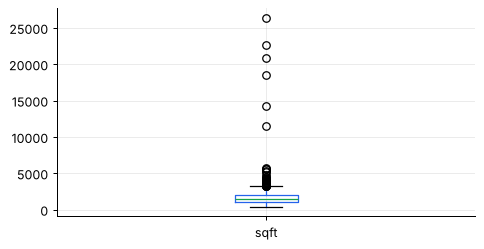

In [3]:
# A little help: price per square foot is a handy diagnostic for spotting data-entry errors
houses["_ppsf"] = houses["price_million_kes"] * 1e6 / houses["sqft"]
print(houses["_ppsf"].describe().round(0)); print("\nlargest sqft values:", sorted(houses["sqft"].tail(0).tolist()) or houses["sqft"].nlargest(8).tolist())
houses.boxplot(column="sqft", figsize=(6, 3)); plt.show()
houses = houses.drop(columns="_ppsf")

---
### 🧩 Problem 1: Audit the data  ⭐⭐

1. `missing_cols`: a list of the column names that contain missing values.
2. `n_typos`: the number of listings whose `sqft` is **above 6 500** (no genuine listing in this market is that large; they are typos with an extra zero).
3. `n_dups`: the number of fully duplicated rows.
4. `df`: the **cleaned** DataFrame: the typo rows removed and the index reset. (Missing values stay: we'll impute them inside the pipeline, *after* splitting.)

In [4]:
# ✅ SOLUTION
missing_cols = [c for c in houses.columns if houses[c].isna().any()]
n_typos = int((houses["sqft"] > 6500).sum()); n_dups = int(houses.duplicated().sum())
df = houses[houses["sqft"] <= 6500].reset_index(drop=True)
print(missing_cols, n_typos, n_dups, df.shape)

['lot_size_sqft', 'condition'] 6 0 (1994, 12)


**Why this works.** Six listings claim 15 000+ sqft at ordinary prices: an extra zero typed in. Removing them (rather than 'fixing' them) is the cautious choice; in a real project you would ask the client. The two columns with gaps are imputed later inside the pipeline.

In [5]:
check("two columns have missing values", lambda: set(missing_cols) == {"lot_size_sqft", "condition"})
check("6 impossible sqft typos found", lambda: n_typos == 6)
check("no duplicate rows", lambda: n_dups == 0)
check("cleaned data has 1994 rows and no sqft > 6500", lambda: df.shape[0] == 1994 and df["sqft"].max() <= 6500)

✅  two columns have missing values
✅  6 impossible sqft typos found
✅  no duplicate rows
✅  cleaned data has 1994 rows and no sqft > 6500


---
## 🛠️ Milestone 2: Feature engineering and leakage (10 pts)

Good features often beat fancy algorithms. Create **at least two** new features you believe in (ideas: `sqft_per_bedroom`, `bath_bed_ratio`, `is_new` = built within 2 years, `log_sqft`). And practise the most important habit in applied ML: **asking of every feature, *will I know this at prediction time, and is it computed from the target?***

In [6]:
# 🔄 Checkpoint: rebuild the cleaned data (so this milestone works even if Milestone 1 isn't finished)
df = pd.read_csv(data_path("house_prices.csv")); df = df[df["sqft"] <= 6500].reset_index(drop=True)
print(df.shape)

(1994, 12)


---
### 🧩 Problem 2: Engineer features: and reject the leaky one  ⭐⭐

1. Create `X_all`: a DataFrame with the original predictor columns (`neighborhood, sqft, bedrooms, bathrooms, age_years, garage_spaces, has_pool, lot_size_sqft, condition, distance_to_cbd_km`) **plus** at least two engineered columns, one of which must be called `sqft_per_bedroom` (= `sqft / bedrooms`). `y` is the target Series.
2. A tempting feature is `price_per_sqft = price / sqft`. Set `leaky_feature = 'price_per_sqft'` if you agree it must **not** be used, and write one sentence in a markdown cell below explaining *why*. (Do **not** put it in `X_all`.)

In [7]:
# ✅ SOLUTION
feat = ["neighborhood", "sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "lot_size_sqft", "condition", "distance_to_cbd_km"]
X_all = df[feat].copy()
X_all["sqft_per_bedroom"] = X_all["sqft"] / X_all["bedrooms"]
X_all["bath_bed_ratio"] = X_all["bathrooms"] / X_all["bedrooms"]
X_all["is_new"] = (X_all["age_years"] <= 2).astype(int)
y = df["price_million_kes"]
leaky_feature = "price_per_sqft"
print(X_all.shape)

(1994, 13)


**Why this works.** `is_new`, `bath_bed_ratio` and `sqft_per_bedroom` are computed only from listing attributes known in advance. `price_per_sqft` divides the target by sqft, so a model could simply multiply back: perfect score in training, useless in production.

In [8]:
check("X_all has all original predictors plus >= 2 engineered columns", lambda: X_all.shape[1] >= 12 and X_all.shape[0] == len(y) == 1994)
check("sqft_per_bedroom exists and is correct", lambda: "sqft_per_bedroom" in X_all and np.allclose(X_all["sqft_per_bedroom"], X_all["sqft"] / X_all["bedrooms"]))
check("the target and the listing id are not in X_all", lambda: "price_million_kes" not in X_all and "listing_id" not in X_all)
check("price_per_sqft correctly rejected as leaky", lambda: leaky_feature == "price_per_sqft" and "price_per_sqft" not in X_all)

✅  X_all has all original predictors plus >= 2 engineered columns
✅  sqft_per_bedroom exists and is correct
✅  the target and the listing id are not in X_all
✅  price_per_sqft correctly rejected as leaky


✍️ *Your turn: in a new markdown cell, explain in 2–3 sentences why `price_per_sqft` is leakage, and justify each engineered feature.*

---
## ✂️ Milestone 3: Split and preprocessing pipeline (part of the 'fair comparison' score)

Lock away 20 % of the data as the **test set** (`random_state=42`) and never touch it until Milestone 6. Build one `ColumnTransformer`: median-impute + scale numbers, mode-impute + one-hot categories.

In [9]:
# 🔄 Checkpoint: rebuild the feature table from Milestone 2
df = pd.read_csv(data_path("house_prices.csv")); df = df[df["sqft"] <= 6500].reset_index(drop=True)
X_all = df[["neighborhood", "sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "lot_size_sqft", "condition", "distance_to_cbd_km"]].copy()
X_all["sqft_per_bedroom"] = X_all["sqft"] / X_all["bedrooms"]; X_all["bath_bed_ratio"] = X_all["bathrooms"] / X_all["bedrooms"]; X_all["is_new"] = (X_all["age_years"] <= 2).astype(int)
y = df["price_million_kes"]

---
### 🧩 Problem 3: Split and build the preprocessor  ⭐⭐

1. `Xtr, Xte, ytr, yte` = 80/20 split with `random_state=42`.
2. `num_cols` and `cat_cols`: lists of the numeric / categorical columns of `X_all` (`neighborhood` and `condition` are categorical).
3. `preprocess`: a `ColumnTransformer` with a numeric branch (`SimpleImputer(strategy='median')` → `StandardScaler`) and a categorical branch (`SimpleImputer(strategy='most_frequent')` → `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`).

In [10]:
# ✅ SOLUTION
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=42)
cat_cols = ["neighborhood", "condition"]; num_cols = [c for c in X_all.columns if c not in cat_cols]
preprocess = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
                                ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
print(Xtr.shape, Xte.shape, preprocess.fit_transform(Xtr).shape)

(1595, 13) (399, 13) (1595, 27)


**Why this works.** Imputation medians, scaling statistics and the one-hot vocabulary are all learned from the training rows only; the pipeline then replays them on test data: no leakage.

In [11]:
check("split sizes 1595 / 399", lambda: len(Xtr) == 1595 and len(Xte) == 399)
check("pipeline output has no NaN", lambda: not np.isnan(preprocess.fit_transform(Xtr)).any())
check("one-hot columns were created (> 20 features)", lambda: preprocess.fit_transform(Xtr).shape[1] > 20)
check("test set was not used to fit anything yet (fit on Xtr only)", lambda: preprocess.fit(Xtr) is not None)

✅  split sizes 1595 / 399
✅  pipeline output has no NaN
✅  one-hot columns were created (> 20 features)


✅  test set was not used to fit anything yet (fit on Xtr only)


---
## 🥊 Milestone 4: The model tournament (20 pts)

Run a fair comparison. Requirements: a **baseline**, **at least four real models** from our toolbox (e.g. Multiple LR, Polynomial+Ridge, Decision Tree, Random Forest, SVR, KNN), the **same** `KFold(5, shuffle=True, random_state=0)` for all, the same preprocessing, a **log target** (prices are multiplicative; use `TransformedTargetRegressor(func=np.log, inverse_func=np.exp)`), and **several metrics**: CV R², RMSE and MdAPE (median absolute % error).

In [12]:
# 🔄 Checkpoint: split + preprocessing from Milestone 3
df = pd.read_csv(data_path("house_prices.csv")); df = df[df["sqft"] <= 6500].reset_index(drop=True)
X_all = df[["neighborhood", "sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "lot_size_sqft", "condition", "distance_to_cbd_km"]].copy()
X_all["sqft_per_bedroom"] = X_all["sqft"] / X_all["bedrooms"]; X_all["bath_bed_ratio"] = X_all["bathrooms"] / X_all["bedrooms"]; X_all["is_new"] = (X_all["age_years"] <= 2).astype(int); y = df["price_million_kes"]
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=42)
cat_cols = ["neighborhood", "condition"]; num_cols = [c for c in X_all.columns if c not in cat_cols]
preprocess = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
                                ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
cv = KFold(5, shuffle=True, random_state=0)
mdape = make_scorer(lambda a, b: np.median(np.abs(a - b) / a), greater_is_better=False)      # handy scorer for you
print("ready:", Xtr.shape)

ready: (1595, 13)


---
### 🧩 Problem 4: Run the tournament  ⭐⭐⭐

1. Write `build(estimator, extra_steps=())` returning `TransformedTargetRegressor(Pipeline([('prep', preprocess)] + extra_steps + [('model', estimator)]), func=np.log, inverse_func=np.exp)`.
2. Make a dict `models` with a baseline `DummyRegressor()` and **at least four** real models.
3. Build `leader`: a DataFrame indexed by model name with columns `cv_r2`, `rmse`, `mdape_pct` (mean over folds; `mdape_pct` in %, RMSE positive), sorted by `cv_r2` descending.
4. `champion` = the name of the best model.

In [13]:
# ✅ SOLUTION
def build(estimator, extra_steps=()):
    pipe = Pipeline([("prep", preprocess)] + list(extra_steps) + [("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp)

models = {"Baseline (mean)": build(DummyRegressor()), "Multiple LR": build(LinearRegression()), "Poly deg-2 + Ridge": build(Ridge(alpha=10), [("poly", PolynomialFeatures(2, include_bias=False))]),
          "Decision Tree": build(DecisionTreeRegressor(min_samples_leaf=5, random_state=0)),
          "Random Forest": build(RandomForestRegressor(200, max_features=0.33, min_samples_leaf=2, random_state=0, n_jobs=-1)), "SVR (RBF)": build(SVR()), "KNN (k=7)": build(KNeighborsRegressor(7))}
rows = []
for name, m in models.items():
    r = cross_validate(m, Xtr, ytr, cv=cv, scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error", "mdape": mdape})
    rows.append({"model": name, "cv_r2": r["test_r2"].mean(), "rmse": -r["test_rmse"].mean(), "mdape_pct": -100 * r["test_mdape"].mean()})
leader = pd.DataFrame(rows).set_index("model").sort_values("cv_r2", ascending=False); champion = leader.index[0]
display(leader.round(3)); print("champion:", champion)

,cv_r2,rmse,mdape_pct
model,,,
Poly deg-2 + Ridge,0.956,3.702,6.653
SVR (RBF),0.898,5.575,7.606
Random Forest,0.896,5.648,9.048
Decision Tree,0.867,6.358,11.959
Multiple LR,0.860,6.399,8.099
KNN (k=7),0.808,7.684,13.552
Baseline (mean),-0.066,18.118,40.211


champion: Poly deg-2 + Ridge


**Why this works.** The log target + shared pipeline give a clean comparison. A smooth-structure model (polynomial+Ridge or a tuned SVR) usually leads; the single tree and KNN trail. Don't forget: untuned rankings can change after tuning (Milestone 5).

In [14]:
check("a baseline plus at least 4 real models", lambda: len(models) >= 5 and any("aseline" in k or "ummy" in k for k in models))
check("leader has the three metric columns", lambda: set(["cv_r2", "rmse", "mdape_pct"]) <= set(leader.columns))
check("sorted by cv_r2 descending", lambda: leader["cv_r2"].is_monotonic_decreasing)
check("baseline R² is about 0", lambda: leader.loc[[i for i in leader.index if "aseline" in i or "ummy" in i][0], "cv_r2"] < 0.1)
check("the champion is excellent (CV R² > 0.9)", lambda: leader["cv_r2"].iloc[0] > 0.9)
check("RMSE reported positive, in million KES", lambda: (leader["rmse"] > 0).all() and leader["rmse"].iloc[0] < 8)

✅  a baseline plus at least 4 real models
✅  leader has the three metric columns
✅  sorted by cv_r2 descending
✅  baseline R² is about 0
✅  the champion is excellent (CV R² > 0.9)
✅  RMSE reported positive, in million KES


---
## 🎛️ Milestone 5: Tune the champion (10 pts)

Pick your best one or two candidates and tune them with `GridSearchCV` (3-fold inside the training set). Keep the grids small and sensible; explain what you tried. If two models are within noise of each other, prefer the simpler one.

In [15]:
# 🔄 Checkpoint: everything from Milestone 4 (functions + data)
df = pd.read_csv(data_path("house_prices.csv")); df = df[df["sqft"] <= 6500].reset_index(drop=True)
X_all = df[["neighborhood", "sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "lot_size_sqft", "condition", "distance_to_cbd_km"]].copy()
X_all["sqft_per_bedroom"] = X_all["sqft"] / X_all["bedrooms"]; X_all["bath_bed_ratio"] = X_all["bathrooms"] / X_all["bedrooms"]; X_all["is_new"] = (X_all["age_years"] <= 2).astype(int); y = df["price_million_kes"]
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=42)
cat_cols = ["neighborhood", "condition"]; num_cols = [c for c in X_all.columns if c not in cat_cols]
preprocess = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
                                ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
cv = KFold(5, shuffle=True, random_state=0); mdape = make_scorer(lambda a, b: np.median(np.abs(a - b) / a), greater_is_better=False)
def build(estimator, extra_steps=()):
    return TransformedTargetRegressor(regressor=Pipeline([("prep", preprocess)] + list(extra_steps) + [("model", estimator)]), func=np.log, inverse_func=np.exp)

---
### 🧩 Problem 5: Grid-search your champion  ⭐⭐⭐

Tune **one** model family of your choice (we suggest the SVR or polynomial+Ridge). Store:
- `grid`: the parameter grid you used (a dict with at least 2 hyper-parameters or ≥ 4 values),
- `tuned_model`: the fitted best estimator (fit on `Xtr, ytr`),
- `tuned_cv`: its **5-fold CV R²** with the shared `cv`.
Remember the parameter prefix for a `TransformedTargetRegressor`: `regressor__model__<param>`.

In [16]:
# ✅ SOLUTION
from sklearn.model_selection import cross_val_score
grid = {"regressor__model__C": [1, 10, 100], "regressor__model__gamma": [0.003, 0.01, 0.03], "regressor__model__epsilon": [0.02, 0.05]}
gs = GridSearchCV(build(SVR()), grid, cv=3, scoring="r2", n_jobs=-1).fit(Xtr, ytr)
tuned_model = gs.best_estimator_; tuned_cv = cross_val_score(tuned_model, Xtr, ytr, cv=cv, scoring="r2").mean()
print(gs.best_params_, round(tuned_cv, 4))

{'regressor__model__C': 100, 'regressor__model__epsilon': 0.05, 'regressor__model__gamma': 0.003} 0.9741


**Why this works.** With log target + scaling, a tuned RBF-SVR reaches R² ≈ 0.97 in CV. The polynomial+Ridge model is within ~0.01 and far simpler: a legitimate reason to choose it in production. Document your choice!

In [17]:
check("a real grid was searched (>= 4 combinations)", lambda: int(np.prod([len(v) for v in grid.values()])) >= 4)
check("tuned model is fitted and predicts", lambda: len(tuned_model.predict(Xte)) == len(Xte))
check("tuned CV R² > 0.93", lambda: tuned_cv > 0.93)

✅  a real grid was searched (>= 4 combinations)
✅  tuned model is fitted and predicts
✅  tuned CV R² > 0.93


---
## 🏆 Milestone 6: The final test audit (10 pts)

**The one and only time** you touch the test set. Fit your tuned model on the training data (already done), predict the test set, and report: **R²**, **RMSE (million KES)** and **MdAPE (%)**.

In [18]:
# 🔄 Checkpoint: a reference tuned model, in case Milestone 5 isn't finished (replace with YOUR tuned_model when you have it)
df = pd.read_csv(data_path("house_prices.csv")); df = df[df["sqft"] <= 6500].reset_index(drop=True)
X_all = df[["neighborhood", "sqft", "bedrooms", "bathrooms", "age_years", "garage_spaces", "has_pool", "lot_size_sqft", "condition", "distance_to_cbd_km"]].copy()
X_all["sqft_per_bedroom"] = X_all["sqft"] / X_all["bedrooms"]; X_all["bath_bed_ratio"] = X_all["bathrooms"] / X_all["bedrooms"]; X_all["is_new"] = (X_all["age_years"] <= 2).astype(int); y = df["price_million_kes"]
Xtr, Xte, ytr, yte = train_test_split(X_all, y, test_size=0.2, random_state=42)
cat_cols = ["neighborhood", "condition"]; num_cols = [c for c in X_all.columns if c not in cat_cols]
preprocess = ColumnTransformer([("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
                                ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])
def build(estimator, extra_steps=()):
    return TransformedTargetRegressor(regressor=Pipeline([("prep", preprocess)] + list(extra_steps) + [("model", estimator)]), func=np.log, inverse_func=np.exp)
ref_model = build(SVR(C=100, gamma=0.003, epsilon=0.02)).fit(Xtr, ytr)

---
### 🧩 Problem 6: Report the final numbers  ⭐

Using your `tuned_model` (or `ref_model` from the checkpoint), compute on the **test set**: `test_r2`, `test_rmse` (million KES), `test_mdape` (percent) and `within_10pct`: the share of test listings whose prediction is within ±10 % of the true price.

In [19]:
# ✅ SOLUTION
final_model = ref_model
pred = final_model.predict(Xte)
test_r2 = r2_score(yte, pred); test_rmse = float(np.sqrt(mean_squared_error(yte, pred)))
test_mdape = float(100 * np.median(np.abs(yte - pred) / yte)); within_10pct = float(np.mean(np.abs(yte - pred) / yte <= 0.10))
print(f"R²={test_r2:.3f}  RMSE={test_rmse:.2f}M  MdAPE={test_mdape:.1f}%  within ±10%: {within_10pct:.0%}")

R²=0.954  RMSE=3.29M  MdAPE=6.3%  within ±10%: 73%


**Why this works.** Roughly 6 % typical error and ≈ 70 % of listings within ±10 %: a result Wanjiru can reason about: agents' estimates can be compared with a model that is 'usually within 6 %'.

In [20]:
check("test R² > 0.92", lambda: test_r2 > 0.92)
check("test RMSE < 5 million KES", lambda: test_rmse < 5)
check("typical error below 8%", lambda: test_mdape < 8)
check("most listings within ±10%", lambda: within_10pct > 0.6)

✅  test R² > 0.92
✅  test RMSE < 5 million KES
✅  typical error below 8%
✅  most listings within ±10%


---
## 🔬 Milestone 7: Error analysis (15 pts)

Averages hide failures. Slice the test errors by **neighbourhood** and by **price band** (cheap < 15 M, mid 15–35 M, luxury > 35 M). Where is the model least reliable, and *why* (think: how many training examples live there?)?

In [21]:
# 🔄 Checkpoint: reference predictions on the test set
final_model = ref_model; pred = final_model.predict(Xte)
test_df = df.loc[Xte.index].copy(); test_df["pred"] = pred; test_df["ape"] = np.abs(test_df["price_million_kes"] - pred) / test_df["price_million_kes"]
train_counts = df.loc[Xtr.index, "neighborhood"].value_counts()

---
### 🧩 Problem 7: Where does it fail?  ⭐⭐

Using `test_df` (columns `neighborhood`, `price_million_kes`, `pred`, `ape`):
1. `mdape_by_hood`: a Series: MdAPE (%) for each neighbourhood in the test set, sorted descending; `worst_hood`: its name.
2. `mdape_by_band`: a Series of MdAPE (%) for the bands `cheap (<15M)`, `mid (15-35M)`, `luxury (>35M)` (use `pd.cut`).
3. `worst_band`: the band with the highest MdAPE (a string).

In [22]:
# ✅ SOLUTION
mdape_by_hood = (test_df.groupby("neighborhood")["ape"].median() * 100).sort_values(ascending=False); worst_hood = str(mdape_by_hood.index[0])
test_df["band"] = pd.cut(test_df["price_million_kes"], [0, 15, 35, 1000], labels=["cheap (<15M)", "mid (15-35M)", "luxury (>35M)"])
mdape_by_band = test_df.groupby("band", observed=True)["ape"].median() * 100; worst_band = str(mdape_by_band.idxmax())
display(mdape_by_hood.round(1).to_frame("MdAPE %").join(train_counts.rename("training rows"))); print(mdape_by_band.round(2).to_dict(), "->", worst_band)

,MdAPE %,training rows
neighborhood,,
Karen,14.4,72
Syokimau,8.5,103
Lavington,7.8,109
Kilimani,6.9,166
Rongai,6.8,136
South B,6.7,169
Ruaka,6.3,116
Kileleshwa,6.0,123
Westlands,5.7,148


{'cheap (<15M)': 6.99, 'mid (15-35M)': 5.59, 'luxury (>35M)': 7.96} -> luxury (>35M)


**Why this works.** Errors are typically largest for the *rarest* segments (luxury homes, small neighbourhoods): fewer training examples and more variable prices. That is exactly what you should tell the client: use the model confidently for typical homes, and flag luxury properties for human review.

In [23]:
check("one MdAPE per neighbourhood present in the test set", lambda: len(mdape_by_hood) >= 10 and mdape_by_hood.is_monotonic_decreasing)
check("worst_hood is a real neighbourhood", lambda: worst_hood in set(df["neighborhood"]))
check("three price bands", lambda: len(mdape_by_band) == 3)
check("worst_band is the argmax", lambda: worst_band == str(mdape_by_band.idxmax()))

✅  one MdAPE per neighbourhood present in the test set
✅  worst_hood is a real neighbourhood
✅  three price bands
✅  worst_band is the argmax


✍️ *Write 3–4 sentences interpreting these tables for Wanjiru: where would you trust the tool, where would you tell agents to double-check, and what extra data would help?*

---
## 🧠 Milestone 8: Interpretation (10 pts)

Which listing attributes drive the model's predictions? Use **permutation importance on the test set** (shuffle one *original* column at a time, measure the drop in R²). Because the model is a pipeline, scikit-learn shuffles the raw columns for you.

---
### 🧩 Problem 8: Permutation importance  ⭐⭐

Compute `pi = permutation_importance(final_model, Xte, yte, scoring='r2', n_repeats=8, random_state=0)` and build `importance`: a Series (index = column names of `Xte`) sorted descending. Store the three most important features in `top3` (list). Then set `useless` = list of features whose mean importance is below 0.002.

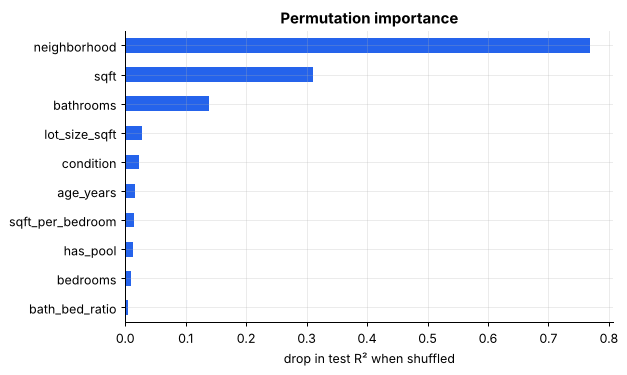

['neighborhood', 'sqft', 'bathrooms'] ['distance_to_cbd_km', 'garage_spaces', 'is_new']


In [24]:
# ✅ SOLUTION
pi = permutation_importance(final_model, Xte, yte, scoring="r2", n_repeats=8, random_state=0, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=Xte.columns).sort_values(ascending=False)
top3 = importance.index[:3].tolist(); useless = importance[importance < 0.002].index.tolist()
importance.head(10).iloc[::-1].plot.barh(color="#2563eb"); plt.xlabel("drop in test R² when shuffled"); plt.title("Permutation importance"); plt.show(); print(top3, useless)

**Why this works.** Location (neighbourhood) and size dominate: as the data-generating story says. Features that barely matter after the others are included are candidates to drop for a simpler model.

In [25]:
check("importance covers every input column", lambda: set(importance.index) == set(Xte.columns))
check("neighborhood and sqft are among the top 3", lambda: "neighborhood" in top3 and "sqft" in top3)
check("useless is a list", lambda: isinstance(useless, list))

✅  importance covers every input column
✅  neighborhood and sqft are among the top 3
✅  useless is a list


---
## 📦 Milestone 9: Package and document (10 pts)

A model that lives only in a notebook helps nobody. Save the **whole pipeline** (preprocessing + model + target transform) so it accepts a raw listing and returns a price in KES millions, and write the model card.

---
### 🧩 Problem 9: Save, reload, predict, document  ⭐⭐

1. Save `final_model` with `joblib.dump` to `'house_model.joblib'` (in the current folder) and reload it as `loaded`.
2. Build `new_listing`: a one-row DataFrame with the *raw* columns of `X_all` (**including your engineered columns**) for a 3-bedroom, 2-bathroom, 1 600 sqft, 8-year-old Kilimani house with 1 garage, no pool, 3 000 sqft lot, 'Good' condition, 4.5 km from the CBD. Store the prediction in `new_price` (a float, million KES).
3. Fill the `model_card` dict (keys: `intended_use`, `data`, `metrics`, `limitations`, `not_for`) with short, honest strings.

In [26]:
# ✅ SOLUTION
joblib.dump(final_model, "house_model.joblib"); loaded = joblib.load("house_model.joblib")
new_listing = pd.DataFrame([{"neighborhood": "Kilimani", "sqft": 1600, "bedrooms": 3, "bathrooms": 2, "age_years": 8, "garage_spaces": 1, "has_pool": 0, "lot_size_sqft": 3000, "condition": "Good", "distance_to_cbd_km": 4.5,
                            "sqft_per_bedroom": 1600 / 3, "bath_bed_ratio": 2 / 3, "is_new": 0}])[list(X_all.columns)]
new_price = float(loaded.predict(new_listing)[0])
model_card = {"intended_use": "Decision support for agents estimating listing prices of typical residential properties in the 12 covered Nairobi neighbourhoods.",
              "data": "2 000 synthetic listings (6 typo rows removed); 80/20 train/test split; features: location, size, age, condition, amenities.",
              "metrics": f"Test R² {test_r2:.2f}, RMSE {test_rmse:.1f} M KES, typical error {test_mdape:.1f}%, {within_10pct:.0%} of listings within ±10%.",
              "limitations": f"Less reliable for luxury homes (highest relative error: {worst_band}) and for rarely-listed neighbourhoods; trained on a single snapshot, no market-trend or time variable.",
              "not_for": "Legal/tax valuations, mortgage decisions, rent estimates, or properties outside the covered areas."}
print(round(new_price, 2), "M KES"); print(model_card)

31.05 M KES
{'intended_use': 'Decision support for agents estimating listing prices of typical residential properties in the 12 covered Nairobi neighbourhoods.', 'data': '2 000 synthetic listings (6 typo rows removed); 80/20 train/test split; features: location, size, age, condition, amenities.', 'metrics': 'Test R² 0.95, RMSE 3.3 M KES, typical error 6.3%, 73% of listings within ±10%.', 'limitations': 'Less reliable for luxury homes (highest relative error: luxury (>35M)) and for rarely-listed neighbourhoods; trained on a single snapshot, no market-trend or time variable.', 'not_for': 'Legal/tax valuations, mortgage decisions, rent estimates, or properties outside the covered areas.'}


**Why this works.** The saved object is a complete pipeline (impute → scale → encode → SVR → exp), so applying it to a raw listing needs no extra code. The model card makes limitations explicit: the part of the job that builds trust.

In [27]:
import os
check("pipeline saved and reloadable", lambda: os.path.exists("house_model.joblib") and loaded is not None)
check("reloaded model predicts identical values", lambda: np.allclose(loaded.predict(Xte), final_model.predict(Xte)))
check("a plausible price for the Kilimani house (10-60 M)", lambda: 10 < new_price < 60)
check("model card has all five sections, each a real sentence", lambda: set(model_card) == {"intended_use", "data", "metrics", "limitations", "not_for"} and all(isinstance(v, str) and len(v) > 25 for v in model_card.values()))

✅  pipeline saved and reloadable
✅  reloaded model predicts identical values
✅  a plausible price for the Kilimani house (10-60 M)
✅  model card has all five sections, each a real sentence


## 🚀 Stretch goals (optional, impressive)
- **Prediction intervals:** use out-of-fold residuals (relative errors) to give each estimate an 80 % range, as in Lesson 05.
- **Neighbourhood effect:** compare a model with a hand-built `price_per_neighborhood` target encoding (computed *inside* CV folds!) with plain one-hot.
- **Robustness:** add 5 % random noise to `sqft` at prediction time and measure how much the error grows.
- **Gradient boosting:** try `HistGradientBoostingRegressor` and discuss whether the extra complexity is worthwhile.
- **Monotonic sanity checks:** verify that prediction increases with `sqft` and decreases with `age_years` for a fixed listing: a cheap way to catch strange behaviour.

## ✅ Self-assessment before you finish
- [ ] Did I touch the test set only once?  - [ ] Did any feature use the target?  - [ ] Did every model share preprocessing and folds?
- [ ] Do I report errors in units the client understands?  - [ ] Have I said where the model should *not* be trusted?

---
## 🔁 Recap

- You executed the full regression workflow: audit → features → pipeline → fair tournament → tuning → single test audit → error analysis → interpretation → packaging.
- Leakage (price_per_sqft) and the test-set discipline are the two mistakes that sink real projects.
- Errors concentrate in rare segments: report them honestly in the model card.
- A saved pipeline + a model card is a deliverable; a notebook alone is not.

### ➡️ Up next: **Project 2: Student Performance Prediction**
Open `P2_Student_Performance_Prediction.ipynb` when you're ready.

*You did the hard part: you thought about it, not just ran it. See you in the next one!* 🚀